# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [33]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [34]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [35]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [36]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ, sep=";")

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
display(df.head())
print(df.shape)
print(df.dtypes)


,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


(65, 4)
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separatorem jest średnik (;). Kolumna wartość ma typ liczbowy (int64). Nazwy kolumn z polskimi znakami wczytały się poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [37]:
# TODO: jakie są zmienne i ile mają wierszy?
print(df["zmienna"].value_counts())


# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [38]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
print(roznica)

rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [39]:
# TODO: statystyki opisowe
display(szeroka.describe())

# TODO: zmiana procentowa 2012 → 2024
zmiana = (szeroka.loc[2024] / szeroka.loc[2012] - 1) * 100
print(zmiana)


# TODO: nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


zmienna
absolwenci ogółem   -41.29
kobiety             -30.22
mężczyźni           -29.14
ogółem              -29.79
uczelnie            -31.82
dtype: float64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05
2017,19281,42990,29029,72019,22,0.60,3273.59
2018,17046,39312,26253,65565,20,0.60,3278.25
2019,15819,38146,26297,64443,19,0.59,3391.74
2020,14082,39170,26155,65325,18,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

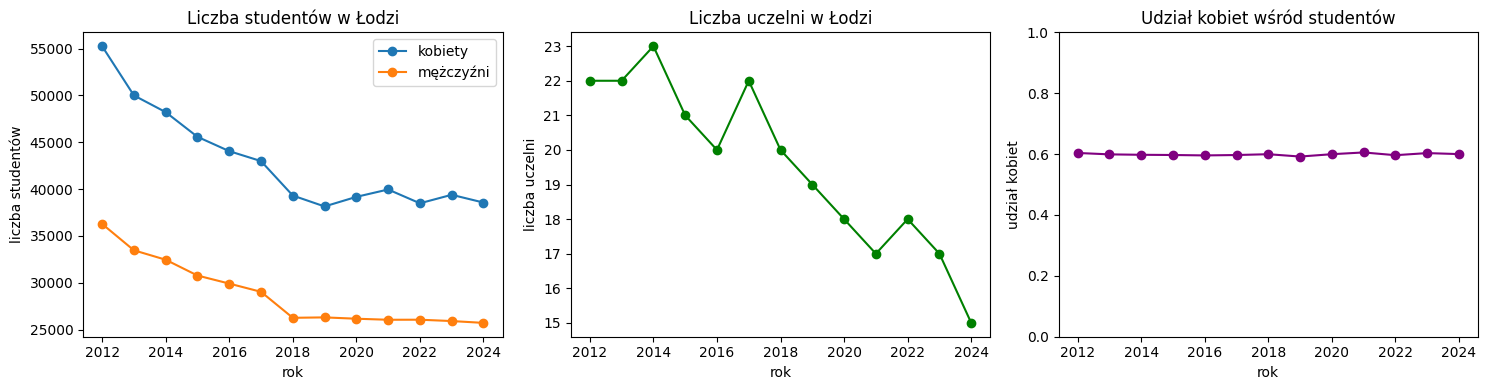

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
axes[0].plot(szeroka.index, szeroka["kobiety"], marker="o", label="kobiety")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], marker="o", label="mężczyźni")
axes[0].set_title("Liczba studentów w Łodzi")
axes[0].set_xlabel("rok")
axes[0].set_ylabel("liczba studentów")
axes[0].legend()

# TODO: wykres 2 — uczelnie
axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o", color="green")
axes[1].set_title("Liczba uczelni w Łodzi")
axes[1].set_xlabel("rok")
axes[1].set_ylabel("liczba uczelni")

# TODO: wykres 3 — udział kobiet
axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", color="purple")
axes[2].set_ylim(0, 1)
axes[2].set_title("Udział kobiet wśród studentów")
axes[2].set_xlabel("rok")
axes[2].set_ylabel("udział kobiet")

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* W latach 2012–2024 liczba studentów w Łodzi wyraźnie spadła, dotyczy to zarówno kobiet, jak i mężczyzn. Spadła też liczba uczelni, z 22 do 15. Udział kobiet wśród studentów przez cały czas utrzymywał się na stałym poziomie ok. 60%.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Mieszkania oddane do użytkowania – powierzchnia · **link:** https://otwarte.miasto.lodz.pl/nieruchomosci/ · **data pobrania:** 22.10.2026

In [41]:
# TODO: wczytanie i przegląd Twojego zbioru
PLIK_MIESZKANIA = "mieszkania-oddane-do-uytkowania-powierzchnia.csv"
upewnij_sie_ze_jest(PLIK_MIESZKANIA)

with open(PLIK_MIESZKANIA, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

mieszkania = pd.read_csv(PLIK_MIESZKANIA, sep=";", decimal=",")
display(mieszkania.head())
print(mieszkania.shape)
print(mieszkania.dtypes)
print(mieszkania.isna().sum())

Plik mieszkania-oddane-do-uytkowania-powierzchnia.csv jest na miejscu.
﻿name;rok;wartość;zmienne
Mieszkania_oddane_do_użytkowania_powierzchnia;2010;106724,8;ogółem łącznie
Mieszkania_oddane_do_użytkowania_powierzchnia;2011;126910,4;ogółem łącznie
Mieszkania_oddane_do_użytkowania_powierzchnia;2012;125062,7;ogółem łącznie
Mieszkania_oddane_do_użytkowania_powierzchnia;2013;250094,2;ogółem łącznie


,name,rok,wartość,zmienne
0,Mieszkania_oddane_do_użytkowania_powierzchnia,2010,106724.80,ogółem łącznie
1,Mieszkania_oddane_do_użytkowania_powierzchnia,2011,126910.40,ogółem łącznie
2,Mieszkania_oddane_do_użytkowania_powierzchnia,2012,125062.70,ogółem łącznie
3,Mieszkania_oddane_do_użytkowania_powierzchnia,2013,250094.20,ogółem łącznie
4,Mieszkania_oddane_do_użytkowania_powierzchnia,2014,220730.10,ogółem łącznie


(210, 4)
name        object
rok          int64
wartość    float64
zmienne     object
dtype: object
name       0
rok        0
wartość    0
zmienne    0
dtype: int64


zmienne
ogółem łącznie                      14
ogółem do 40 m2                     14
ogółem od 40,1 do 60 m2             14
ogółem od 60,1 do 80 m2             14
ogółem od 80,1 m2                   14
rynek pierwotny łącznie             14
rynek pierwotny do 40 m2            14
rynek pierwotny od 40,1 do 60 m2    14
rynek pierwotny od 60,1 do 80 m2    14
rynek pierwotny od 80,1 m2          14
rynek wtórny łącznie                14
rynek wtórny do 40 m2               14
rynek wtórny od 40,1 do 60 m2       14
rynek wtórny od 60,1 do 80 m2       14
rynek wtórny od 80,1 m2             14
Name: count, dtype: int64
rok
2010   0.00
2011   0.00
2012   0.00
2013   0.00
2014   0.00
2015   0.00
2016   0.00
2017   0.00
2018   0.00
2019   0.00
2020   0.00
2021   0.00
2022   0.00
2023   0.00
dtype: float64


zmienne,ogółem do 40 m2,"ogółem od 40,1 do 60 m2","ogółem od 60,1 do 80 m2","ogółem od 80,1 m2",ogółem łącznie,rynek pierwotny do 40 m2,"rynek pierwotny od 40,1 do 60 m2","rynek pierwotny od 60,1 do 80 m2","rynek pierwotny od 80,1 m2",rynek pierwotny łącznie,rynek wtórny do 40 m2,"rynek wtórny od 40,1 do 60 m2","rynek wtórny od 60,1 do 80 m2","rynek wtórny od 80,1 m2",rynek wtórny łącznie
count,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00
mean,56648.43,120729.34,67218.76,40550.03,285146.56,16149.46,45595.48,37209.09,20404.77,119358.79,40498.97,75133.86,30009.68,20145.26,165787.77
std,27683.15,47904.88,26686.69,14663.48,114065.22,14709.62,24974.41,16942.03,7648.22,60918.39,14194.29,25344.01,10829.60,7709.06,56848.40
min,18435.60,46543.80,25642.00,16103.40,106724.80,1317.30,11132.50,12341.00,8474.80,35547.30,16570.00,33039.90,12749.90,5507.80,67867.60
25%,38529.67,92298.65,56327.38,33519.45,228071.12,4576.35,29524.85,27016.33,14440.52,82162.78,33939.18,60502.32,23452.00,17659.53,138880.78
50%,53601.55,117496.20,66403.60,41593.20,271352.55,10346.65,42107.25,37254.00,21465.40,104507.30,43108.40,76348.45,31822.20,20432.65,173236.20
75%,76829.77,153894.52,89071.38,53515.78,374943.50,28827.55,60930.60,51180.77,24663.55,168758.90,48552.28,95582.30,37328.50,24676.83,209099.15
max,104181.00,195460.90,108545.80,59333.60,458502.00,39471.50,89521.70,64327.40,31450.90,223172.10,65877.00,112100.00,44218.40,34436.80,245581.80


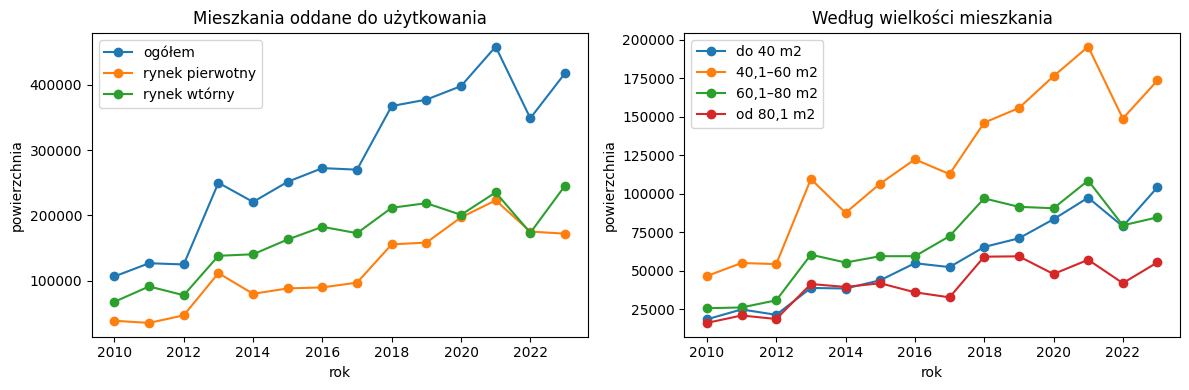

In [42]:
# TODO: przekształcenia, statystyki i wykresy
print(mieszkania["zmienne"].value_counts())

mieszkania_szeroka = mieszkania.pivot(index="rok", columns="zmienne", values="wartość")

roznica = mieszkania_szeroka["rynek pierwotny łącznie"] + mieszkania_szeroka["rynek wtórny łącznie"] - mieszkania_szeroka["ogółem łącznie"]
print(roznica.round(2))

display(mieszkania_szeroka.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(mieszkania_szeroka.index, mieszkania_szeroka["ogółem łącznie"], marker="o", label="ogółem")
axes[0].plot(mieszkania_szeroka.index, mieszkania_szeroka["rynek pierwotny łącznie"], marker="o", label="rynek pierwotny")
axes[0].plot(mieszkania_szeroka.index, mieszkania_szeroka["rynek wtórny łącznie"], marker="o", label="rynek wtórny")
axes[0].set_title("Mieszkania oddane do użytkowania")
axes[0].set_xlabel("rok")
axes[0].set_ylabel("powierzchnia")
axes[0].legend()

axes[1].plot(mieszkania_szeroka.index, mieszkania_szeroka["ogółem do 40 m2"], marker="o", label="do 40 m2")
axes[1].plot(mieszkania_szeroka.index, mieszkania_szeroka["ogółem od 40,1 do 60 m2"], marker="o", label="40,1–60 m2")
axes[1].plot(mieszkania_szeroka.index, mieszkania_szeroka["ogółem od 60,1 do 80 m2"], marker="o", label="60,1–80 m2")
axes[1].plot(mieszkania_szeroka.index, mieszkania_szeroka["ogółem od 80,1 m2"], marker="o", label="od 80,1 m2")
axes[1].set_title("Według wielkości mieszkania")
axes[1].set_xlabel("rok")
axes[1].set_ylabel("powierzchnia")
axes[1].legend()

plt.tight_layout()
plt.show()

✍️ **Wnioski:** W latach 2010–2023 powierzchnia mieszkań oddanych do użytkowania w Łodzi wzrosła prawie czterokrotnie, z wyraźnym skokiem w 2013 roku i spadkiem w 2022 po rekordowym 2021. Rynek pierwotny rósł szybciej niż wtórny i w 2020 roku był prawie tak duży jak wtórny. Najwięcej przybywało mieszkań o powierzchni 40,1–60 m².

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [43]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


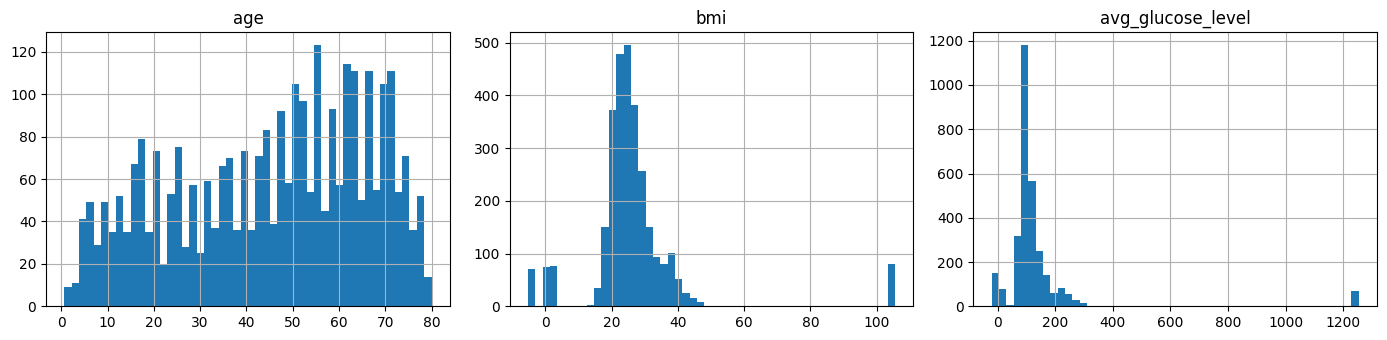

In [44]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
display(pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(bins=50, figsize=(14, 3.5), layout=(1, 3))
plt.tight_layout()
plt.show()


✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Możliwe są wartości wieku, bo 0,67 roku (ok. 8 miesięcy), a 80 lat to możliwy wiek. Niemożliwe są wartości BMI i glukozy: BMI nie może być ujemne, a 105,6 jest nierealne, tak samo jak ujemna glukoza i 1254,6 mg/dl.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [45]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)

# TODO: liczebności
print(zle_bmi.sum(), zla_glukoza.sum(), zly_wiek.sum())
print((zle_bmi | zla_glukoza | zly_wiek).sum())

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

300 300 0
560


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


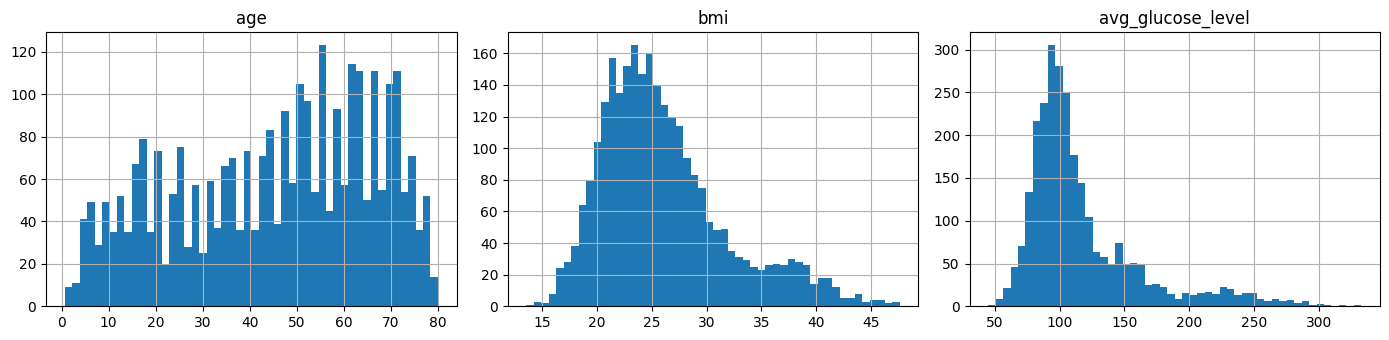

In [46]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?

display(pacjenci[LICZBOWE].describe())

pacjenci[LICZBOWE].hist(bins=50, figsize=(14, 3.5), layout=(1, 3))
plt.tight_layout()
plt.show()

Po zamianie wartości niemożliwych na NaN znikły skrajne słupki na histogramach, a odchylenie standardowe glukozy spadło ze 181 do 44.

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

Text(0.5, 0, 'glukoza [mg/dl]')

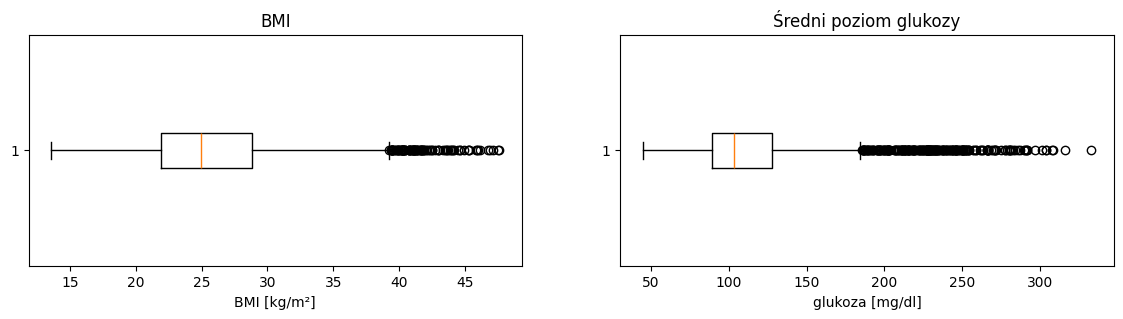

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal")
axes[0].set_title("BMI")
axes[0].set_xlabel("BMI [kg/m²]")

axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal")
axes[1].set_title("Średni poziom glukozy")
axes[1].set_xlabel("glukoza [mg/dl]")

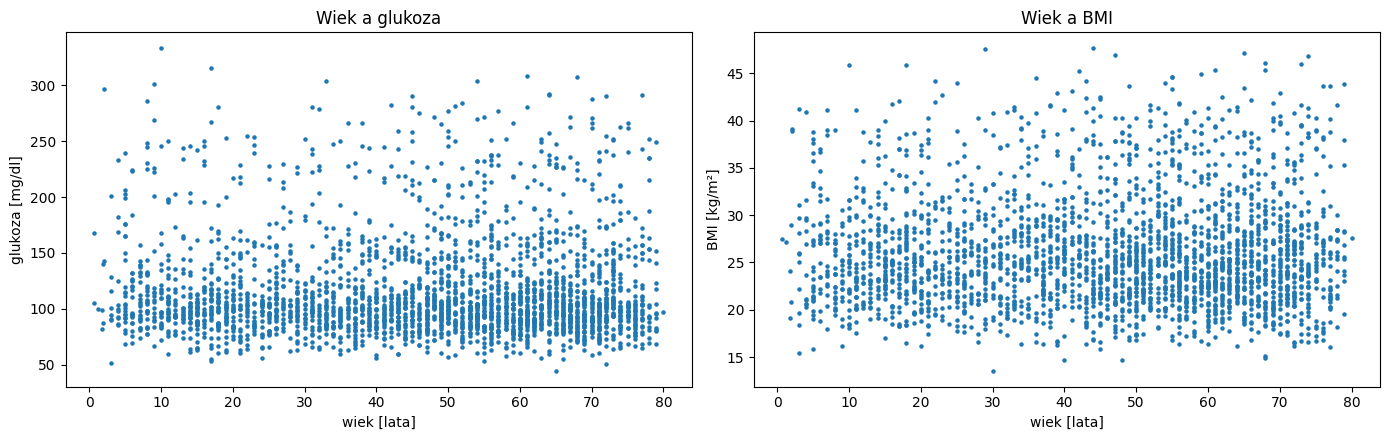

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], s=5)
axes[0].set_title("Wiek a glukoza")
axes[0].set_xlabel("wiek [lata]")
axes[0].set_ylabel("glukoza [mg/dl]")

axes[1].scatter(pacjenci["age"], pacjenci["bmi"], s=5)
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("wiek [lata]")
axes[1].set_ylabel("BMI [kg/m²]")

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?

Więcej punktów poza wąsami jest dla glukozy niż dla BMI. W obu przypadkach leżą tylko po prawej stronie pudełka, czyli są to wartości wyższe od typowych.

2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

Wysokie wartości glukozy występują w każdym wieku, nie tylko u starszych osób. 10-latek ze średnią glukozą ponad 300 mg/dl to raczej rzadki przypadek niż błąd, bo ta wartość mieści się w możliwym zakresie.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [49]:
def maska_iqr(s, k=1.5):
    # TODO
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s, prog=3):
    # TODO
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    # TODO
    med = s.median()
    mad = (s - med).abs().median()
    z = 0.6745 * (s - med) / mad
    return z.abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [50]:
# TODO: tabela porównawcza `porownanie`
porownanie = pd.DataFrame(index=LICZBOWE)
porownanie["IQR 1,5"] = [maska_iqr(pacjenci[kol]).sum() for kol in LICZBOWE]
porownanie["IQR 3"] = [maska_iqr(pacjenci[kol], k=3).sum() for kol in LICZBOWE]
porownanie["z-score"] = [maska_z(pacjenci[kol]).sum() for kol in LICZBOWE]
porownanie["MAD"] = [maska_mad(pacjenci[kol]).sum() for kol in LICZBOWE]
porownanie["skośność"] = pacjenci[LICZBOWE].skew()
porownanie

,"IQR 1,5",IQR 3,z-score,MAD,skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Glukoza ma dużą skośność (1,8) i długi prawy ogon, widać to na histogramie. Przez to metody dają różne wyniki: z-score wykrywa tylko 62 obserwacje, bo średnia i odchylenie są zawyżone przez wartości odstające, a IQR i MAD wykrywają ich dużo więcej (235 i 223). Wiek ma skośność bliską zera (−0,33) i rozkład w miarę równomierny, bez wartości skrajnych, dlatego żadna metoda nic nie wykrywa.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

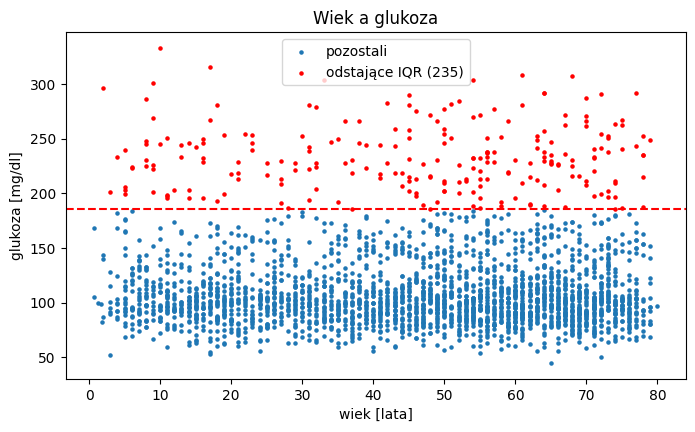

235


In [51]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
glukoza = pacjenci["avg_glucose_level"]
odstajace = maska_iqr(glukoza)
q1, q3 = glukoza.quantile([0.25, 0.75])
gorna = q3 + 1.5 * (q3 - q1)

plt.figure(figsize=(8, 4.5))
plt.scatter(pacjenci.loc[~odstajace, "age"], glukoza[~odstajace], s=5, label="pozostali")
plt.scatter(pacjenci.loc[odstajace, "age"], glukoza[odstajace], s=5, color="red", label=f"odstające IQR ({odstajace.sum()})")
plt.axhline(gorna, color="red", linestyle="--")
plt.title("Wiek a glukoza")
plt.xlabel("wiek [lata]")
plt.ylabel("glukoza [mg/dl]")
plt.legend()
plt.show()

print((glukoza > gorna).sum())

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

0.2170212765957447
0.21095334685598377


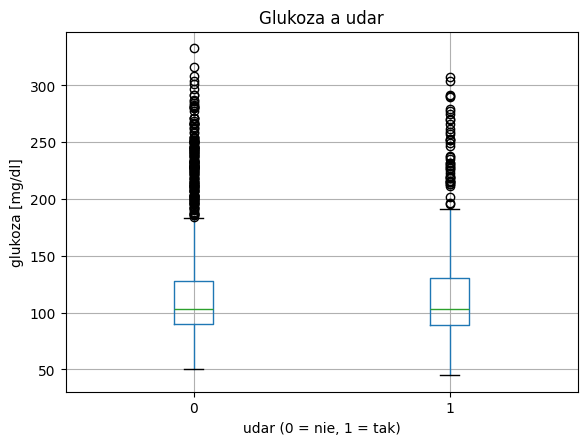

In [52]:
# TODO: odsetek udarów w obu grupach
pozostali = ~odstajace & glukoza.notna()
print(pacjenci.loc[odstajace, "stroke"].mean())
print(pacjenci.loc[pozostali, "stroke"].mean())

# TODO: boxplot glukozy w podziale na stroke
pacjenci.boxplot(column="avg_glucose_level", by="stroke")
plt.title("Glukoza a udar")
plt.suptitle("")
plt.xlabel("udar (0 = nie, 1 = tak)")
plt.ylabel("glukoza [mg/dl]")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie. Są to prawdziwe, choć rzadkie wartości, a nie błędy. Wysoka glukoza może być związana z udarem, więc usunięcie tych pacjentów mogłoby wyciąć ważną informację. W tych danych odsetek udarów w obu grupach jest podobny.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [53]:
# TODO: tabela krzyżowa
pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"])

# TODO: maski
dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")

print(dziecko_pali.sum(), maluch_student.sum())
display(pacjenci[dziecko_pali])
display(pacjenci[maluch_student])

15 1


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
352,A810636,Male,14.00,0,0,False,children,Rural,203.26,NaN,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
578,A161666,Male,3.00,0,0,False,children,Urban,NaN,15.47,smokes,0
600,A623587,Male,10.00,0,0,False,children,Urban,NaN,20.93,smokes,0
613,A892803,Male,13.00,0,0,False,children,Urban,132.17,25.04,smokes,0
741,A560170,Male,13.00,0,0,False,children,Urban,243.95,25.59,smokes,0
767,A390530,Male,13.00,0,0,False,children,Urban,91.28,28.47,smokes,0


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* W tabeli krzyżowej podejrzane jest, że kilkanaście osób z work_type = children ma status smokes, bo dzieci nie powinny palić. Podejrzany jest też 1,8-latek, który jest studentem i jak wynika z danych, kiedyś palił.

IQR i z-score by tego nie wykryły. Każda wartość osobno jest poprawna (np. wiek 2 lata, „smokes”), a nielogiczna jest dopiero ich kombinacja. Te metody patrzą tylko na skrajne wartości jednej zmiennej liczbowej.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [54]:
from scipy.stats import chi2

# TODO
X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)

print(len(X), prog)
print((d2 > prog).sum())

udzial = (Z[d2 > prog] ** 2).idxmax(axis=1)
print(udzial.value_counts())

2440 11.344866730144373
73
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

31
                   age   bmi  avg_glucose_level
age               1.00  0.02               0.01
bmi               0.02  1.00              -0.02
avg_glucose_level 0.01 -0.02               1.00


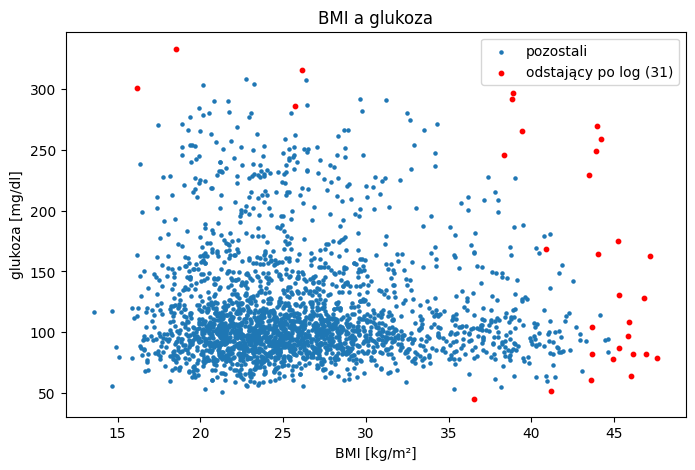

In [55]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
print((d2_log > prog).sum())

print(X.corr())

# TODO: wykres punktowy
odst_log = d2_log > prog

plt.figure(figsize=(8, 5))
plt.scatter(X.loc[~odst_log, "bmi"], X.loc[~odst_log, "avg_glucose_level"], s=5, label="pozostali")
plt.scatter(X.loc[odst_log, "bmi"], X.loc[odst_log, "avg_glucose_level"], s=10, color="red", label=f"odstający po log ({odst_log.sum()})")
plt.title("BMI a glukoza")
plt.xlabel("BMI [kg/m²]")
plt.ylabel("glukoza [mg/dl]")
plt.legend()
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Nie, Mahalanobis nie dałby tu wiele więcej. Cechy są prawie nieskorelowane, więc dla takich danych odległość Mahalanobisa daje prawie to samo co euklidesowa.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [56]:
# TODO (dla chętnych)
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
etykiety = iso.fit_predict(X_log)

iso_odstajace = etykiety == -1
odleglosc_odstajace = (d2_log > prog).values

print(iso_odstajace.sum())
print((iso_odstajace & odleglosc_odstajace).sum())

25
19


Isolation Forest wskazał 25 pacjentów, a odległość euklidesowa po logarytmie 31. Obie metody wskazują jednocześnie 19 pacjentów, czyli większość odstających jest wspólna.

## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [57]:
# TODO: ramka flagi
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = zle_bmi | zla_glukoza | zly_wiek
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"])
flagi["nielogiczna_kategoria"] = dziecko_pali | maluch_student
flagi["odlegly_od_srodka"] = (d2_log > prog).reindex(oryginal.index, fill_value=False)

print(flagi.sum())
print(flagi.any(axis=1).sum())

niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | zamienić na NaN | To błędy pomiaru, a nie prawdziwi pacjenci, więc nie mogą wpływać na średnie. |
| wysoka glukoza (IQR) | zostawić (ewentualnie log) | To prawdziwe, tylko rzadkie wartości, a rozkład glukozy jest po prostu prawoskośny. |
| nielogiczne kategorie | usunąć wiersze | Nie wiadomo, która wartość jest błędna, więc nie da się ich poprawić (16 pacjentów). |
| odlegli od środka |oznaczyć flagą| Kombinacja jest nietypowa, ale to nie musi być błąd, więc lepiej zachować informację. |